Task 1: Load the Olivetti Faces dataset using sklearn.datasets.fetch_olivetti_faces. Print the total number of samples, unique target subjects, feature dimensions, and plot a 4 x 5 grid of sample faces labeled with their subject IDs.

Explanation: Loads the faces with fetch_olivetti_faces and keeps three parts of it: X (faces.data, the 400 faces flattened into 4,096 pixel values between 0 and 1), y (faces.target, the subject ID from 0 to 39) and images (faces.images, the same faces as 64 x 64 grids, which are needed for drawing pictures). The imports for the whole notebook (PCA, the three classifiers, the voting ensemble and the evaluation metrics) are also placed in this cell. I print the number of samples, the number of unique subjects and the feature dimensions to confirm there are 400 faces, 40 people and 4,096 features, and then draw a 4 x 5 grid using the first picture of each of the first 20 subjects, with the subject ID as the title of each face.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total number of samples: 400
Unique target subjects: 40
Feature dimensions: 4096 (64 x 64 pixels)
Images per subject: 10


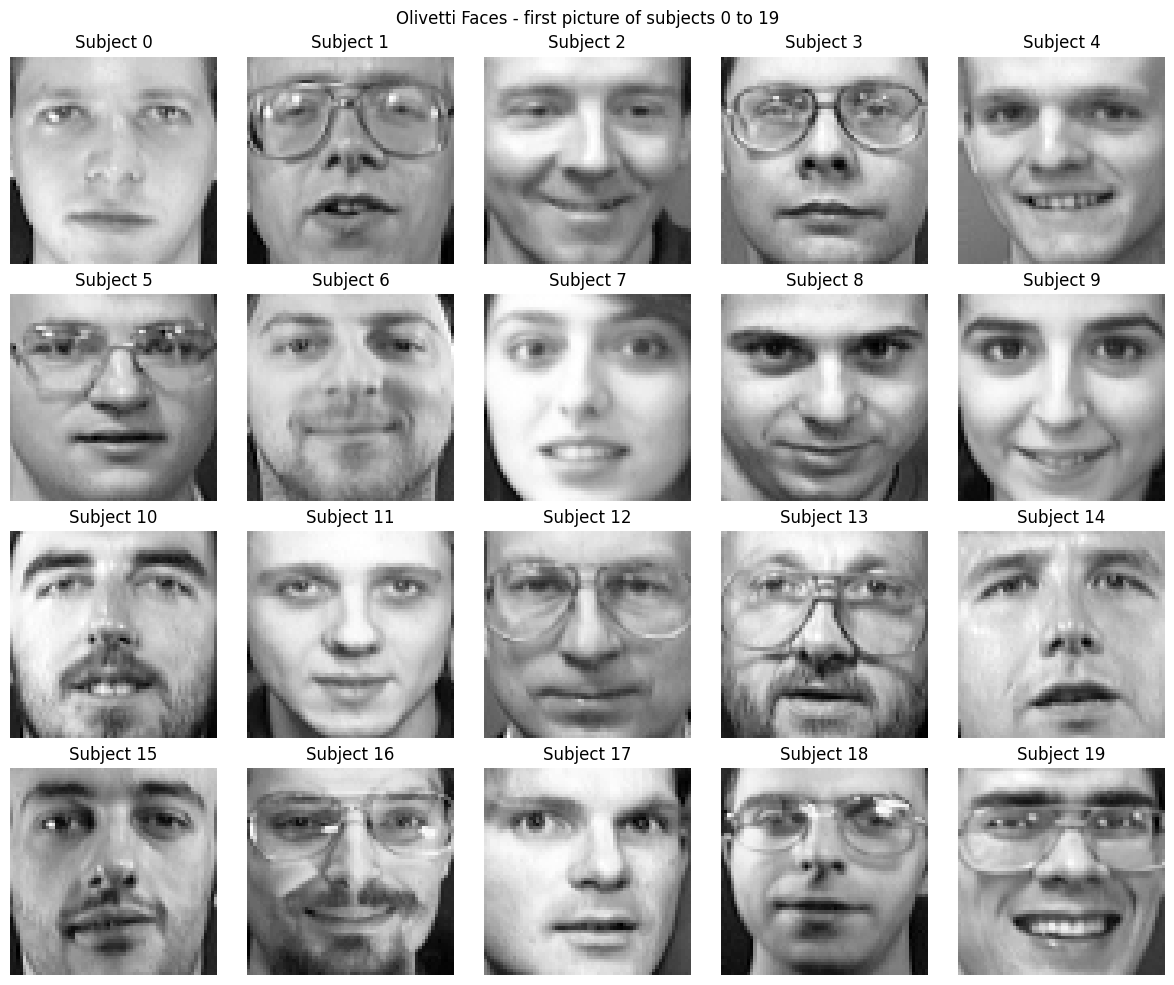

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

faces = fetch_olivetti_faces(shuffle=False, random_state=42)
X = faces.data
y = faces.target
images = faces.images

print(f"Total number of samples: {X.shape[0]}")
print(f"Unique target subjects: {len(np.unique(y))}")
print(f"Feature dimensions: {X.shape[1]} ({images.shape[1]} x {images.shape[2]} pixels)")
print(f"Images per subject: {np.bincount(y)[0]}")

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for subject_id, ax in enumerate(axes.ravel()):
    ax.imshow(images[np.where(y == subject_id)[0][0]], cmap="gray")
    ax.set_title(f"Subject {subject_id}")
    ax.axis("off")
plt.suptitle("Olivetti Faces - first picture of subjects 0 to 19")
plt.tight_layout()
plt.show()

Task 2: Fit a full PCA model on the dataset. Plot both the individual explained variance ratio and the cumulative explained variance curve versus the number of principal components. Determine and print the exact number of components required to preserve 90%, 95%, and 99% of the cumulative variance.

Explanation: Fits PCA() with no n_components on all 400 faces so that every component is kept, and takes explained_variance_ratio_ (the share of the total variance that each component captures). The cumulative variance is the running total of these ratios from np.cumsum. I plot the individual ratios on the left, where they drop off quickly, and the cumulative curve on the right with dotted lines at 90%, 95% and 99%, so that the elbow (where adding more components stops helping much) can be seen. The number of components for each level is found with np.argmax(cumulative >= level) + 1, which is the first position where the running total reaches the level (plus 1 because counting starts at 0). This PCA is fitted on all of the faces only because this task describes the structure of the data, and the PCA used for classification in task 5 is fitted on the training set only.

Components needed for 90% of the variance: 66 out of 4096
Components needed for 95% of the variance: 123 out of 4096
Components needed for 99% of the variance: 260 out of 4096


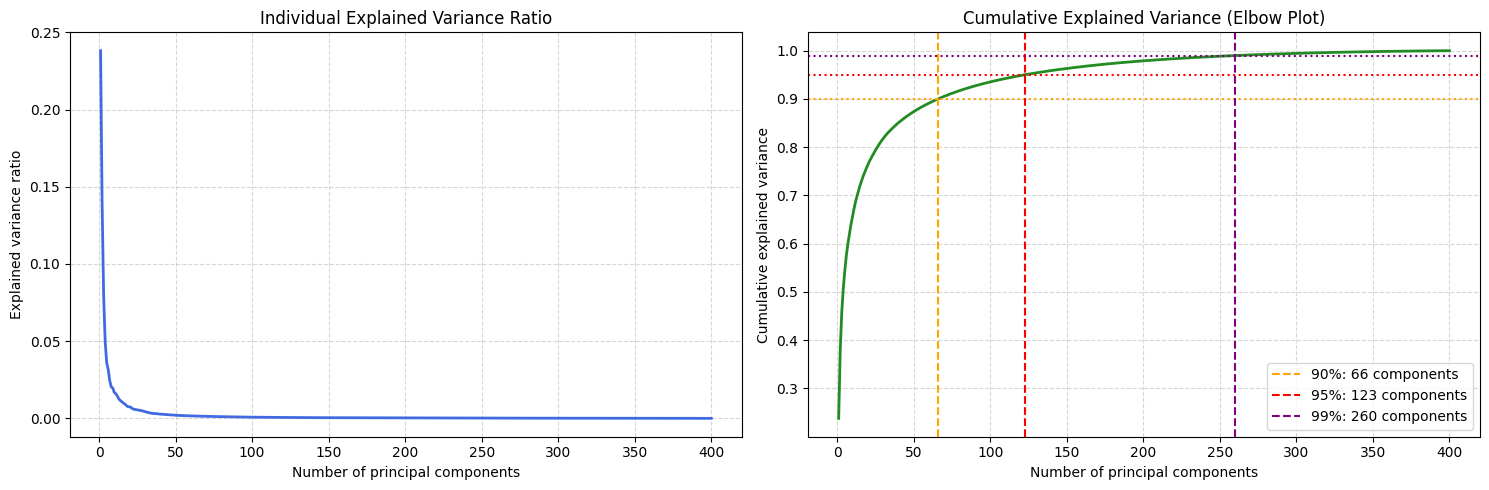

In [2]:
pca_full = PCA(random_state=42)
pca_full.fit(X)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

n_needed = {}
for level in [0.90, 0.95, 0.99]:
    n_needed[level] = int(np.argmax(cumulative >= level) + 1)
    print(f"Components needed for {int(level * 100)}% of the variance: {n_needed[level]} out of {X.shape[1]}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(range(1, len(explained) + 1), explained, color="royalblue", linewidth=2)
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Individual explained variance Ratio")
axes[0].grid(axis="both", linestyle="--", alpha=0.5)

axes[1].plot(range(1, len(cumulative) + 1), cumulative, color="forestgreen", linewidth=2)
for level, color in zip(n_needed, ["orange", "red", "purple"]):
    axes[1].axhline(level, color=color, linestyle=":")
    axes[1].axvline(n_needed[level], color=color, linestyle="--", label=f"{int(level * 100)}%: {n_needed[level]} components")
axes[1].set_xlabel("Number of principal components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Cumulative explained Variance (Elbow plot)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Task 3: Select 5 representative facial images. Compress and reconstruct them using PCA with varying numbers of components; e.g., k in {10, 50, 100, 200, 300}. Plot a grid comparing the original images against their reconstructions across each component threshold, and compute/plot the Mean Squared Error (MSE) between original and reconstructed faces as a function of k.

Explanation: Picks the first picture of subjects 0, 10, 20, 30 and 39 so that the five faces are five different people. For each k in {10, 50, 100, 200, 300} it fits a PCA with n_components=k, compresses the faces with fit_transform (which turns each 4,096 pixel face into only k numbers) and rebuilds them with inverse_transform (which turns the k numbers back into 4,096 pixels). The MSE is the average of the squared pixel differences between the original and the rebuilt face, so a smaller MSE means a closer match. I compute it for the 5 selected faces and also for all 400 faces. The first figure is a 5 x 6 grid with the originals in the left column and the reconstructions for each k to the right, so the loss of detail at small k can be seen directly, and the second figure plots the MSE against k. The PCA here is fitted on all of the faces because this task is only about how well the faces can be compressed, and a table of the exact MSE values is printed at the end.

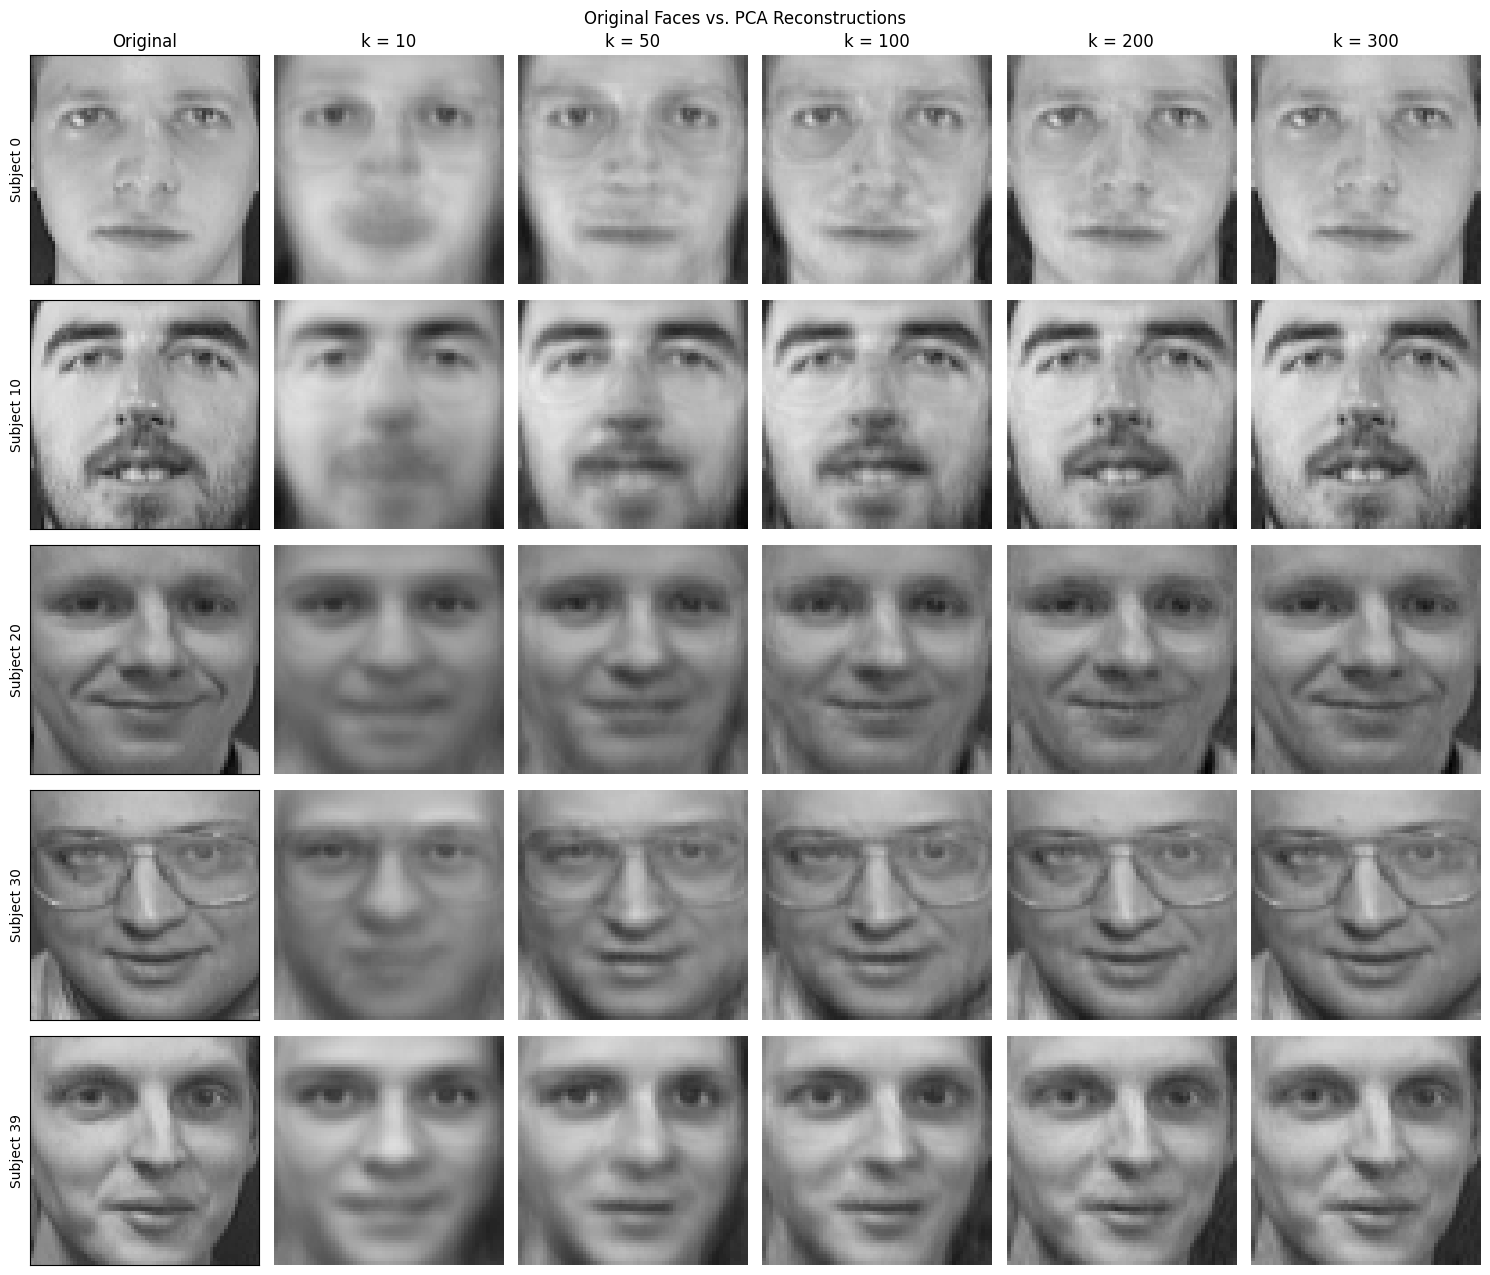

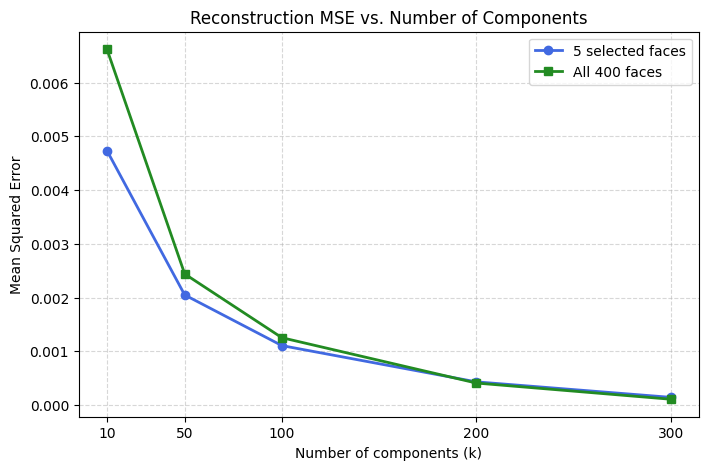

  k  MSE (5 faces)  MSE (all 400)
 10       0.004735       0.006622
 50       0.002048       0.002439
100       0.001105       0.001252
200       0.000431       0.000409
300       0.000143       0.000107


In [3]:
selected_idx = [int(np.where(y == s)[0][0]) for s in [0, 10, 20, 30, 39]]
ks = [10, 50, 100, 200, 300]

recon = {}
mse_selected, mse_all = [], []
for k in ks:
    pca_k = PCA(n_components=k, random_state=42)
    X_rebuilt = pca_k.inverse_transform(pca_k.fit_transform(X))
    recon[k] = X_rebuilt[selected_idx]
    mse_selected.append(np.mean((X[selected_idx] - X_rebuilt[selected_idx]) ** 2))
    mse_all.append(np.mean((X - X_rebuilt) ** 2))

fig, axes = plt.subplots(5, 6, figsize=(15, 13))
for row, idx in enumerate(selected_idx):
    axes[row, 0].imshow(X[idx].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title("Original" if row == 0 else "")
    axes[row, 0].set_ylabel(f"Subject {y[idx]}")
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    for col, k in enumerate(ks):
        axes[row, col + 1].imshow(recon[k][row].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
        axes[row, col + 1].set_title(f"k = {k}" if row == 0 else "")
        axes[row, col + 1].axis("off")
plt.suptitle("Original Faces vs. PCA Reconstructions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(ks, mse_selected, marker="o", color="royalblue", linewidth=2, label="5 selected faces")
plt.plot(ks, mse_all, marker="s", color="forestgreen", linewidth=2, label="All 400 faces")
plt.xlabel("Number of components (k)")
plt.ylabel("Mean Squared Error")
plt.title("Reconstruction MSE vs. Number of Components")
plt.xticks(ks)
plt.legend()
plt.grid(linestyle="--", alpha=0.5)
plt.show()

print(pd.DataFrame({"k": ks, "MSE (5 faces)": np.round(mse_selected, 6), "MSE (all 400)": np.round(mse_all, 6)}).to_string(index=False))

Task 4: Extract the principal components (eigenvectors) from your fitted PCA model. Reshape the first 15 principal components back into 64 x 64 grids and visualize them in a 3 x 5 plot grid ("Eigenfaces"). Annotate each plot with the percentage of total variance explained by that specific component.

Explanation: Takes components_ from the full PCA fitted in task 2. Each component is a list of 4,096 weights, one for each pixel, so the first 15 can be reshaped into 64 x 64 grids and drawn like pictures, which are called eigenfaces. Every face in the dataset can be rebuilt as the average face plus a mix of these eigenfaces. I draw them in a 3 x 5 grid and put the component number and its explained_variance_ratio_ times 100 in the title of each one, and I also print how much variance the 15 components explain together. The first ones show the biggest differences between the pictures, and the later ones show smaller and smaller details.

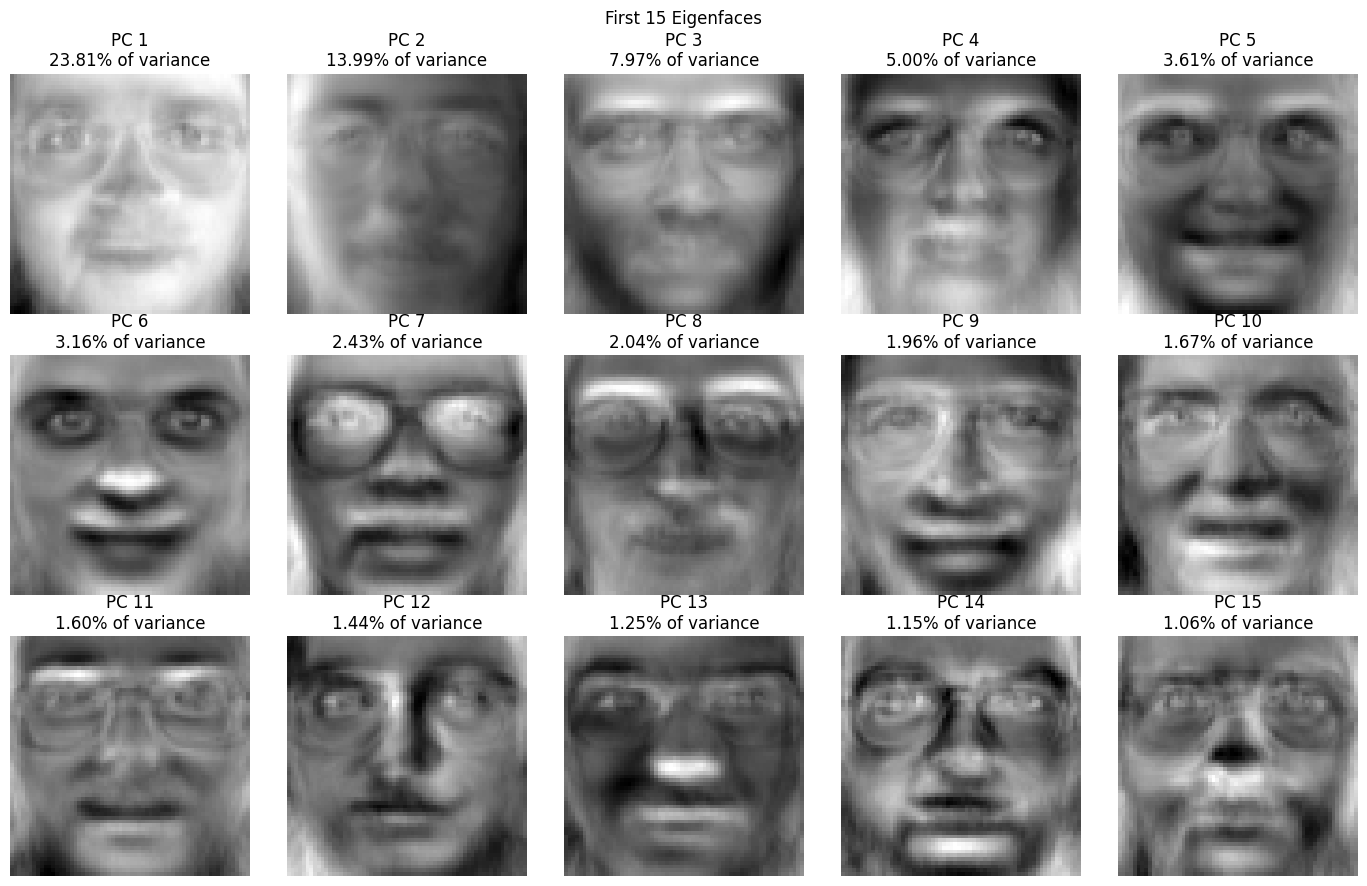

First 15 components together explain 72.12% of the variance


In [4]:
eigenfaces = pca_full.components_[:15].reshape(15, 64, 64)

fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigenfaces[i], cmap="gray")
    ax.set_title(f"PC {i + 1}\n{explained[i] * 100:.2f}% of variance")
    ax.axis("off")
plt.suptitle("First 15 Eigenfaces")
plt.tight_layout()
plt.show()

print(f"First 15 components together explain {explained[:15].sum() * 100:.2f}% of the variance")

Task 5: Perform a stratified train/test split (80/20). Train a LogisticRegression classifier on the raw 4,096-dimensional feature vectors and on the PCA-reduced feature vectors using the 95% variance threshold fitted strictly on the training set. Evaluate and print the test accuracy and training time for both, and visualize the performance comparison in a dual-axis bar plot (Accuracy vs. Training Time).

Explanation: Splits the data 80/20 with stratify=y so that every person has 8 faces in the training set and 2 in the test set (320 and 80 faces. Builds a function, evaluate_model, that prints the test accuracy, the number of wrongly classified test faces and the training time, so the identical output is used in tasks 5, 6 and 7. The first Logistic Regression is trained on the raw 4,096 pixels. For the second one, PCA(n_components=0.95) is fitted on the training set only, which keeps the smallest number of components that explain 95% of the variance, and the test faces are only transformed with the already fitted PCA, so nothing from the test set leaks into training. The pixels already go from 0 to 1, so I do not use a scaler. The training time is measured with time.time(), and for the PCA model it includes the time to fit the PCA so the comparison is fair. The result is plotted in a dual-axis bar chart with accuracy on the left axis and training time in seconds on the right axis.

Training set shape: (320, 4096)
Testing set shape: (80, 4096)

Logistic Regression (Raw): accuracy = 0.9625, wrong faces = 3 of 80, training time = 24.04s
PCA kept 111 components out of 4096 (0.78s to fit)
Logistic Regression (PCA): accuracy = 0.9625, wrong faces = 3 of 80, training time = 1.53s


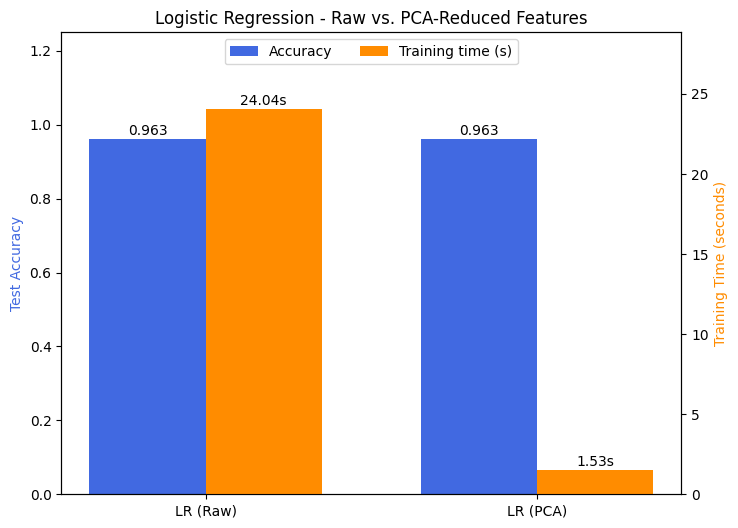

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}\n")

def evaluate_model(name, y_pred, train_time):
    acc = accuracy_score(y_test, y_pred)
    print(f"{name}: accuracy = {acc:.4f}, wrong faces = {(y_pred != y_test).sum()} of {len(y_test)}, training time = {train_time:.2f}s")
    return acc

start = time.time()
lr_raw = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
lr_raw_time = time.time() - start
lr_raw_acc = evaluate_model("Logistic Regression (Raw)", lr_raw.predict(X_test), lr_raw_time)

start = time.time()
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train)
pca_fit_time = time.time() - start
X_test_pca = pca_95.transform(X_test)
print(f"PCA kept {pca_95.n_components_} components out of {X_train.shape[1]} ({pca_fit_time:.2f}s to fit)")

start = time.time()
lr_pca = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_pca, y_train)
lr_pca_time = pca_fit_time + (time.time() - start)
y_pred_lr = lr_pca.predict(X_test_pca)
lr_pca_acc = evaluate_model("Logistic Regression (PCA)", y_pred_lr, lr_pca_time)

names = ["LR (Raw)", "LR (PCA)"]
accs = [lr_raw_acc, lr_pca_acc]
times = [lr_raw_time, lr_pca_time]
x_pos = np.arange(2)

fig, ax1 = plt.subplots(figsize=(8, 6))
bars1 = ax1.bar(x_pos - 0.175, accs, 0.35, color="royalblue", label="Accuracy")
ax1.set_ylabel("Test Accuracy", color="royalblue")
ax1.set_ylim(0, 1.25)
ax2 = ax1.twinx()
bars2 = ax2.bar(x_pos + 0.175, times, 0.35, color="darkorange", label="Training time (s)")
ax2.set_ylabel("Training Time (seconds)", color="darkorange")
ax2.set_ylim(0, max(times) * 1.2)
for bar, val in zip(bars1, accs):
    ax1.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center")
for bar, val in zip(bars2, times):
    ax2.text(bar.get_x() + bar.get_width() / 2, val + max(times) * 0.01, f"{val:.2f}s", ha="center")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(names)
ax1.set_title("Logistic Regression - Raw vs. PCA-Reduced Features")
ax1.legend([bars1, bars2], ["Accuracy", "Training time (s)"], loc="upper center", ncol=2)
plt.show()

Task 6: Train a SVC with an RBF kernel on the PCA-reduced features (95% variance). Record its training time and test accuracy, and plot a confusion matrix or classification summary comparing its predictions against the linear baseline.

Explanation: Trains an SVC with kernel="rbf" on the same PCA features from task 5, which were fitted on the training set only. The RBF kernel lets the model draw a curved boundary instead of the straight one used by Logistic Regression. The training time is the SVC fit time plus the PCA fit time from task 5, so it can be compared with the Logistic Regression (PCA) time, and I evaluate it with the function from task 5. Then I print a classification report for the SVC and for the Logistic Regression and plot their two confusion matrices side by side (true subject in the rows, predicted subject in the columns), where a perfect model has everything on the diagonal and every dot off the diagonal is a face given to the wrong person. The numbers inside the cells are left out because 40 x 40 values would not be readable.

SVC RBF (PCA): accuracy = 0.9375, wrong faces = 5 of 80, training time = 0.83s

===== Logistic Regression (PCA) =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      0.50      0.67         2
           5       0.67      1.00      0.80         2
           6       1.00      1.00      1.00         2
           7       0.67      1.00      0.80         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      0.50      0.67         2
          13       1.00      1.00      1.00         2
          14       0.67      1.00      0.80         2
          15     

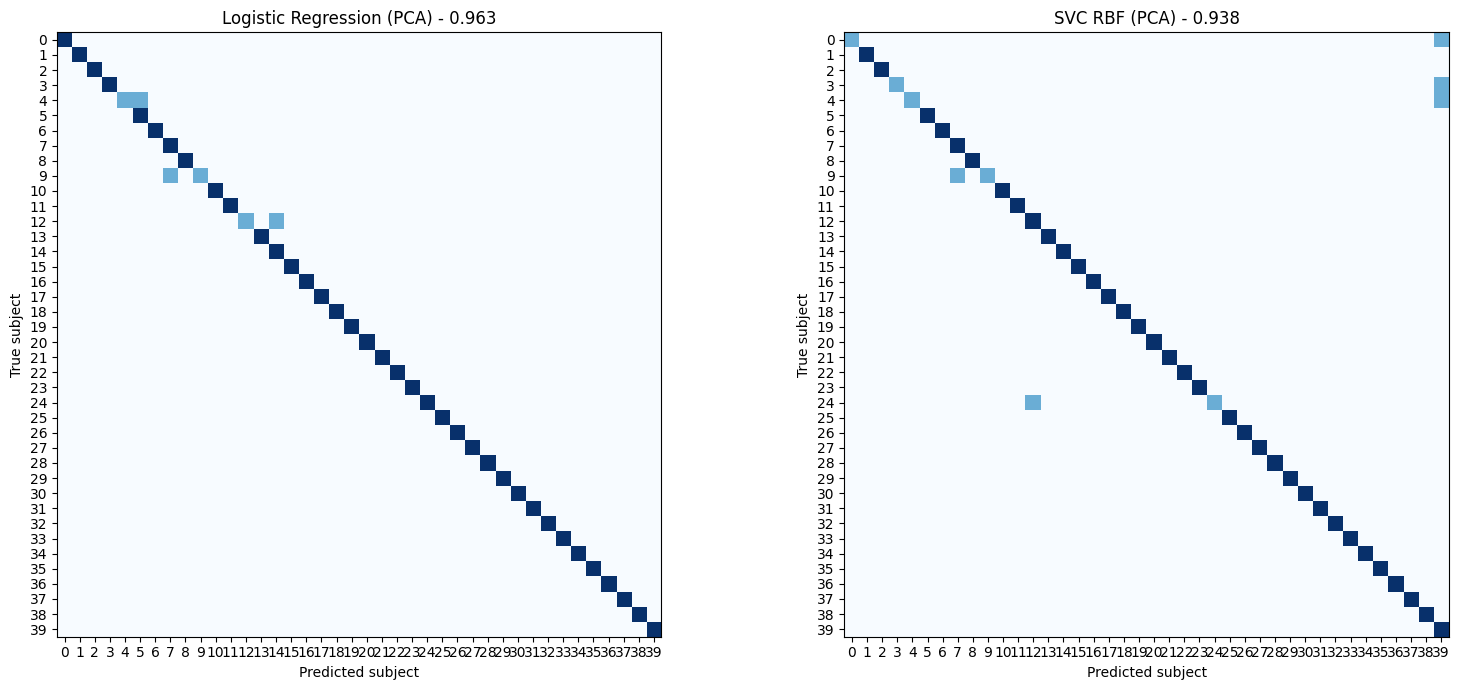

In [6]:
start = time.time()
svc_rbf = SVC(kernel="rbf", random_state=42).fit(X_train_pca, y_train)
svc_time = pca_fit_time + (time.time() - start)
y_pred_svc = svc_rbf.predict(X_test_pca)
svc_acc = evaluate_model("SVC RBF (PCA)", y_pred_svc, svc_time)

print("\n===== logistic regression (PCA) =====")
print(classification_report(y_test, y_pred_lr, zero_division=0))
print("===== SVC RBF (PCA) =====")
print(classification_report(y_test, y_pred_svc, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, pred, title in zip(axes, [y_pred_lr, y_pred_svc], [f"Logistic Regression (PCA) - {lr_pca_acc:.3f}", f"SVC RBF (PCA) - {svc_acc:.3f}"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=np.arange(40))).plot(ax=ax, include_values=False, colorbar=False, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted subject")
    ax.set_ylabel("True subject")
plt.tight_layout()
plt.show()

Task 7: Construct a VotingClassifier (soft voting) combining a Polynomial Kernel SVM (degree=2), an RBF Kernel SVM, and a RandomForestClassifier (n_estimators=100). Train the ensemble on the PCA-reduced features, record training time and accuracy, and compare its performance against the single linear and non-linear models.

Explanation: Builds a VotingClassifier with voting="soft" from a polynomial SVC (kernel="poly", degree=2), an RBF SVC and a RandomForestClassifier with 100 trees. Soft voting averages the predicted probabilities of the three models and picks the class with the highest average, so both SVCs are created with probability=True. The ensemble is trained on the PCA features from task 5 and evaluated with the function from task 5, and its training time includes the PCA fit time like the other PCA models. At the end I print a table with the accuracy, training time and number of wrong faces of Logistic Regression, the SVC and the ensemble on the same PCA features, so the ensemble can be compared directly with the single linear and non-linear models.

In [8]:
ensemble = VotingClassifier(
    estimators=[("poly_svm", SVC(kernel="poly", degree=2, probability=True, random_state=42)),
                ("rbf_svm", SVC(kernel="rbf", probability=True, random_state=42)),
                ("rf", RandomForestClassifier(n_estimators=100, random_state=42))],
    voting="soft",
)

start = time.time()
ensemble.fit(X_train_pca, y_train)
ens_time = pca_fit_time + (time.time() - start)
y_pred_ens = ensemble.predict(X_test_pca)
ens_acc = evaluate_model("Soft Voting Ensemble (PCA)", y_pred_ens, ens_time)

comparison = pd.DataFrame({
    "Test accuracy": [lr_pca_acc, svc_acc, ens_acc],
    "Training time": [lr_pca_time, svc_time, ens_time],
    "Wrong faces": [(y_pred_lr != y_test).sum(), (y_pred_svc != y_test).sum(), (y_pred_ens != y_test).sum()],
}, index=["Logistic Regression (PCA)", "SVC RBF (PCA)", "Soft Voting Ensemble (PCA)"]).round(4)
print()
print(comparison)

Soft Voting Ensemble (PCA): accuracy = 0.9500, wrong faces = 4 of 80, training time = 1.73s

                            Test accuracy  Training time  Wrong faces
Logistic Regression (PCA)          0.9625         1.5294            3
SVC RBF (PCA)                      0.9375         0.8315            5
Soft Voting Ensemble (PCA)         0.9500         1.7314            4


Task 8: Create a single summary bar plot comparing Accuracy (primary y-axis) and Training Time in seconds (secondary y-axis) across all four model configurations: Logistic Regression (Raw Features), Logistic Regression (PCA-Reduced), Support Vector Classifier with RBF Kernel (PCA-Reduced) and Soft Voting Ensemble (PCA-Reduced).

Explanation: Collects the test accuracy and training time of the four models from tasks 5, 6 and 7 into lists and draws one bar chart. Each model has two bars next to each other, a blue one for the test accuracy on the left y-axis and an orange one for the training time in seconds on the right y-axis, which is made with twinx(). The value of every bar is written above it. The training times of the three PCA models include the time to fit the PCA, so all four models are compared fairly. A table with the same numbers is printed under the plot.

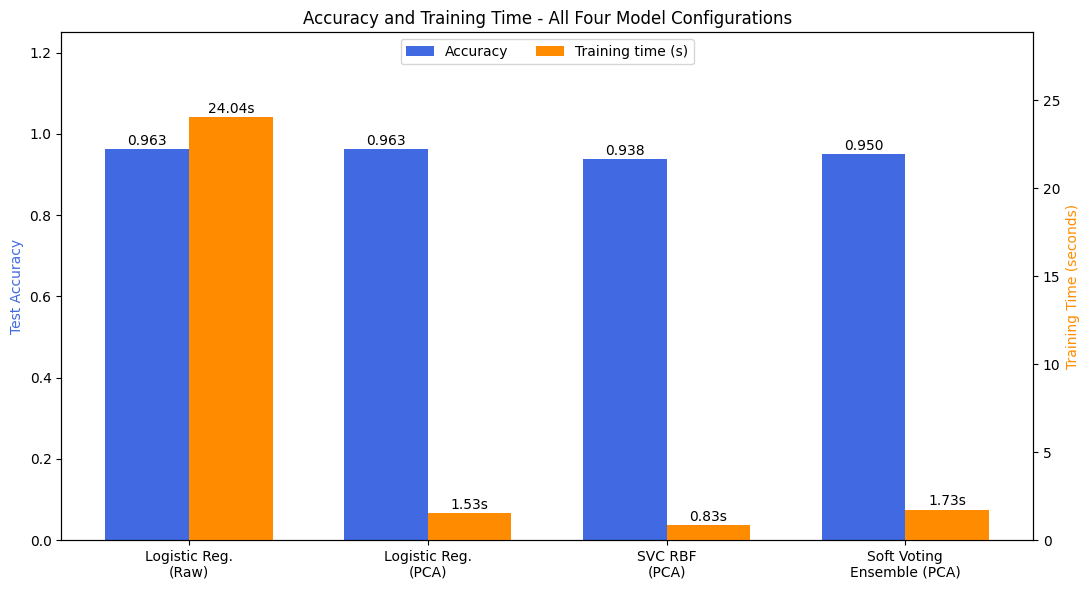

                            Test accuracy  Training time (s)
Logistic Reg. (Raw)                0.9625            24.0402
Logistic Reg. (PCA)                0.9625             1.5294
SVC RBF (PCA)                      0.9375             0.8315
Soft Voting Ensemble (PCA)         0.9500             1.7314


In [9]:
models = ["Logistic Reg.\n(Raw)", "Logistic Reg.\n(PCA)", "SVC RBF\n(PCA)", "Soft Voting\nEnsemble (PCA)"]
accuracies = [lr_raw_acc, lr_pca_acc, svc_acc, ens_acc]
train_times = [lr_raw_time, lr_pca_time, svc_time, ens_time]
x_pos = np.arange(len(models))

fig, ax1 = plt.subplots(figsize=(11, 6))
bars1 = ax1.bar(x_pos - 0.175, accuracies, 0.35, color="royalblue")
ax1.set_ylabel("Test Accuracy", color="royalblue")
ax1.set_ylim(0, 1.25)
ax2 = ax1.twinx()
bars2 = ax2.bar(x_pos + 0.175, train_times, 0.35, color="darkorange")
ax2.set_ylabel("Training Time (seconds)", color="darkorange")
ax2.set_ylim(0, max(train_times) * 1.2)
for bar, val in zip(bars1, accuracies):
    ax1.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center")
for bar, val in zip(bars2, train_times):
    ax2.text(bar.get_x() + bar.get_width() / 2, val + max(train_times) * 0.01, f"{val:.2f}s", ha="center")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models)
ax1.legend([bars1, bars2], ["Accuracy", "Training time (s)"], loc="upper center", ncol=2)
ax1.set_title("Accuracy and Training Time - all Four Model Configurations")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"Test accuracy": accuracies, "Training time (s)": train_times},
                   index=[m.replace("\n", " ") for m in models]).round(4))